# #16 Time Shift

* Your task is to convert each ticket to its user's local time and then calculate the ticket volume by local hour of day (0–23) across the full dataset.
* What local hour has the most ticket submissions? (24-hour format, 0–23) 

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
tickets = pd.read_csv("time_shift_tickets.csv")
users = pd.read_csv("time_shift_users.csv")

In [3]:
tickets.info()

<class 'pandas.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   ticket_id         22000 non-null  int64
 1   user_id           22000 non-null  int64
 2   submitted_at_utc  22000 non-null  str  
dtypes: int64(2), str(1)
memory usage: 515.8 KB


In [4]:
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   user_id   700 non-null    int64
 1   country   700 non-null    str  
 2   timezone  700 non-null    str  
dtypes: int64(1), str(2)
memory usage: 16.5 KB


In [5]:
tickets.sample(5).to_clipboard(sep="\t", index=False)

In [6]:
users.sample(5)

,user_id,country,timezone
597,598,Iceland,"GMT +00:00 — Monrovia, Reykjavik"
689,690,South Africa,"GMT +02:00 — Harare, Pretoria"
430,431,Mexico,"GMT -06:00 — Guadalajara, Mexico City, Monterrey"
403,404,Mexico,"GMT -06:00 — Guadalajara, Mexico City, Monterrey"
389,390,South Korea,GMT +09:00 — Seoul


In [7]:
tickets["submitted_at_utc"] = pd.to_datetime(
    tickets["submitted_at_utc"]
)

df = tickets.merge(
    users[["user_id", "timezone"]],
    on="user_id",
    how="left"
)

df["utc_offset"] = df["timezone"].apply(lambda x: x[3:10])

# df[["timezone", "utc_offset"]].sample(5)

df = df.assign(
    utc_offset_td = pd.to_timedelta(df["utc_offset"] + ":00"), #convert to timedelta
    submitted_at_local = lambda x: x["submitted_at_utc"] + x["utc_offset_td"], #add timedelta to utc time
    local_hour = lambda x: x["submitted_at_local"].dt.hour #extract local hour
    )

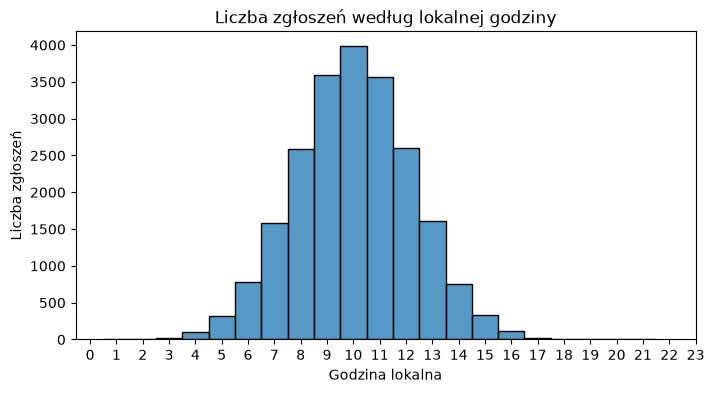

In [8]:
plt.figure(figsize=(8, 4))
sns.histplot(
    data=df,
    x="local_hour",
    bins=24,
    discrete=True
)

plt.xticks(range(24))
plt.title("Liczba zgłoszeń według lokalnej godziny")
plt.xlabel("Godzina lokalna")
plt.ylabel("Liczba zgłoszeń")
plt.show()